# C0 · synthetic round-width arm: comparison with the mechanism study (exploratory; run locally, no training)

Reads the 48 round-width runs (trained on the pod by `C0_SYNTH_round_width*.ipynb`) and the 36 mechanism-study runs they pair
with (B0 = round σ₀, A∥, A⊥ at N = 1,600 and 6,400, same seeds), from one folder: `RUN_ROOT` (default: the repo's
`weights/C0/SYNTH`). Needs no GPU and no images. The parameters and setup cells are copied verbatim from the training notebook, so
`SYNTH_PROTOCOL` (hash b1804b3e5ef74a65) and the round-width spec (`RW_HASH`) are recomputed and checked against every run's `DONE`.

## 0. Parameters, setup and run table (verbatim from the training notebook)

In [1]:
import os

SMOKE_TEST = False       # True: 64 px images, tiny networks, 40 iterations; checks the pipeline only
GPU = None               # physical GPU index for this notebook (e.g. 0); None = first visible GPU
RUN_ROOT = os.environ.get("C0_SYNTH_ROOT", os.path.abspath("../../weights/C0/SYNTH"))   # repo weights/C0/SYNTH (this notebook sits in notebooks/C0_SYNTH_RW)
ITERS = 30000            # optimisation steps per run, the same for every N (ISBI runs: about 29,600)
BATCH_SIZE = 8
PROGRESS_BAR = True      # one progress bar per run (loss, it/s, ETA)
SAVE_MODELS = True       # final weights per run (High ~120 MB); set False to keep only predictions

In [2]:
import sys, json, math, time, hashlib, platform
from pathlib import Path
if GPU is not None:
    os.environ["CUDA_VISIBLE_DEVICES"] = str(GPU)
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import cv2
import matplotlib.pyplot as plt

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP_DTYPE = (torch.bfloat16 if DEVICE.type == "cuda" and torch.cuda.is_bf16_supported() else
             torch.float16 if DEVICE.type == "cuda" else None)
torch.backends.cudnn.benchmark = True

IMG = 64 if SMOKE_TEST else 256
H_C = W_C = IMG
K = 2
LM_NAMES = ["corner", "edge point"]
SIGMA0_PX = 1.5 if SMOKE_TEST else 4.0
RATIO = 4.0
N_TRAIN = [20, 40] if SMOKE_TEST else [100, 400, 1600, 6400]
N_TEST = 40 if SMOKE_TEST else 1000
TIER_BASE = {"Extra-low": 4, "High": 8} if SMOKE_TEST else {"Extra-low": 8, "Low": 16, "High": 64}
SEEDS = [1, 2]
ARMS = ["B0", "Apar", "Aperp"]
if SMOKE_TEST:
    ITERS = 40
    RUN_ROOT = str(Path("c0_synth_smoke").resolve())
R_WIN = 4 if SMOKE_TEST else 15
GROSS_PX = 1e9 if SMOKE_TEST else 10.0
GEN = {"texture_amp": 0.15, "texture_sigma_frac": 3 / 256, "pixel_noise": 0.05, "blur_frac": 1 / 256,
       "wedge_angle_deg": [60.0, 120.0], "wedge_len_frac": 0.2, "bump_height_frac": 0.04, "bump_width_frac": 0.06,
       "edge_disk_radius_frac": 0.28, "edge_disk_offset_frac": 0.5, "contrast": [0.4, 0.8], "min_landmark_distance_frac": 0.35, "margin_frac": 0.22,
       "train_stream": 1, "test_stream": 2}
SYNTH_PROTOCOL = {
    "study": "C0 synthetic mechanism study (plan section 9), exploratory", "image_px": IMG, "landmarks": LM_NAMES, "generator": GEN,
    "reference_axes": {"corner": "wedge bisector", "edge point": "edge tangent at the apex"},
    "sigma0_px": SIGMA0_PX, "ratio": RATIO, "arms": {"B0": "round sigma0^2 I", "Apar": "long axis along the reference axis",
                                                     "Aperp": "long axis across the reference axis"},
    "n_train": N_TRAIN, "n_test": N_TEST, "tiers": TIER_BASE, "seeds": SEEDS,
    "target_loss_net_decoders": "verbatim from the C0 arm A source (make_targets, mass_normalised_mse, UNet 4 levels, decoders)",
    "optimiser": {"name": "AdamW", "lr": 1e-3, "weight_decay": 1e-4, "warmup_iters": max(1, ITERS // 20),
                  "schedule": "cosine to 1e-6 per iteration"},
    "iters": ITERS, "batch_size": BATCH_SIZE, "batch_stream": "default_rng([seed, N, iteration]) -> indices in range(N)",
    "augmentation": None, "convergence_check": "MRE (quadratic) on the first 50 training images every ITERS/10 iterations",
    "intensity": "per-image z-score", "amp": "bf16 autocast if supported, else fp16 with GradScaler",
    "decoders": ["argmax", "quadratic", "softargmax_local", "gaussfit"], "primary_decoder": "quadratic",
    "decoder_window_radius_px": R_WIN, "gross_failure_px": GROSS_PX, "smoke_test": SMOKE_TEST,
}
SYNTH_HASH = hashlib.sha256(json.dumps(SYNTH_PROTOCOL, sort_keys=True).encode()).hexdigest()[:16]
Path(RUN_ROOT).mkdir(parents=True, exist_ok=True)
ENV_INFO = {"python": sys.version.split()[0], "torch": torch.__version__, "cuda": torch.version.cuda, "device": str(DEVICE),
            "gpu": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else None, "platform": platform.platform()}
print("synthetic protocol", SYNTH_HASH, "| device", DEVICE, "| amp", AMP_DTYPE, "| smoke", SMOKE_TEST, "| RUN_ROOT", RUN_ROOT)

# round-width arm: not part of SYNTH_PROTOCOL (which stays identical to the mechanism study), but hashed and recorded separately
EXPECTED_SYNTH_HASH = "b1804b3e5ef74a65"   # the mechanism study's protocol at the pod settings
assert SMOKE_TEST or SYNTH_HASH == EXPECTED_SYNTH_HASH, f"SYNTH_PROTOCOL differs from the mechanism study: {SYNTH_HASH}"
RW_FACTORS = [2 ** -1, 2 ** -0.5, 2 ** 0.5, 2 ** 1]          # width multiples of sigma0 (log-spaced; 0.5 and 2 = oval short / long axis)
RW_FACTOR = {f"R{f:.2f}": f for f in RW_FACTORS}              # arm name -> factor (R0.50, R0.71, R1.41, R2.00)
RW_N = [20, 40] if SMOKE_TEST else [1600, 6400]
RW_SPEC = {"arm": "round-width (exploratory)", "target": "round (w * sigma0)^2 I, unit peak, as B0", "width_factors": RW_FACTORS,
           "arm_names": list(RW_FACTOR), "n_train": RW_N, "tiers": TIER_BASE, "seeds": SEEDS, "paired_with": "B0, Apar, Aperp of the "
           "mechanism study (same tier, N, seed)", "synth_protocol_hash": SYNTH_HASH}
RW_HASH = hashlib.sha256(json.dumps(RW_SPEC, sort_keys=True).encode()).hexdigest()[:16]
print("round-width arm", RW_HASH, "| widths (px):", [round(f * SIGMA0_PX, 2) for f in RW_FACTORS], "| N:", RW_N)

synthetic protocol b1804b3e5ef74a65 | device cpu | amp None | smoke False | RUN_ROOT C:\Users\nearl\Desktop\probable-umbrella\weights\C0\SYNTH
round-width arm b06677c2e887a63e | widths (px): [2.0, 2.83, 5.66, 8.0] | N: [1600, 6400]


In [3]:
BASE_TABLE = pd.DataFrame([{"run_id": f"C0_SYNTH_{tier}_N{n}_{arm}_s{seed}", "tier": tier, "base": base, "n_train": n, "arm": arm, "seed": seed}
                           for tier, base in TIER_BASE.items() for n in N_TRAIN for seed in SEEDS for arm in ARMS])   # mechanism study
RUN_TABLE = pd.DataFrame([{"run_id": f"C0_SYNTH_{tier}_N{n}_{arm}_s{seed}", "tier": tier, "base": base, "n_train": n, "arm": arm, "seed": seed,
                           "width_factor": RW_FACTOR[arm]}
                          for tier, base in TIER_BASE.items() for n in RW_N for seed in SEEDS for arm in RW_FACTOR])  # this arm
assert RUN_TABLE.run_id.is_unique and not set(RUN_TABLE.run_id) & set(BASE_TABLE.run_id)
PAIRED = BASE_TABLE[BASE_TABLE.n_train.isin(RW_N)]          # B0 / Apar / Aperp runs the analysis pairs with


## 1. Comparison with the mechanism study (needs all 48 round-width runs and the 36 paired runs in `RUN_ROOT`)

* Per run and landmark, as in the mechanism study: primary-decoder errors projected on u (reference axis) and v (across it); gross
  failures (|e| > 10 px) removed and reported as a rate; SD along u and v.
* **Round size response.** Δ log SD = log SD(round run) − log SD(paired B0), same tier, N, seed, landmark and direction, against
  x = log w. Usable if both cells have ≤ 5 % gross failures. Per tier × N × landmark × direction: **a_narrow** = least-squares slope
  through the origin over the narrowed widths (w < 1) and **a_wide** over the widened widths (w > 1), defined as in the mechanism
  study (> 0: a narrower blob reduces the spread / a wider blob increases it; 1 = full transfer).
* **Round vs oval along the same axis and width.** The oval's short axis is 2 px (σ₀/2), the same as round R0.50; its long axis is
  8 px (2σ₀), the same as R2.00. Per tier, N, seed, landmark and direction: Δ(oval axis) − Δ(round of the same width) on that
  direction. < 0 on the narrow axis: the oval narrows better than a round blob; > 0 on the wide axis: the oval's long axis costs
  more than a round blob of that width. All arms of one tier, N and seed see the same images in the same order, so this is paired.
* **Overall error and trainability.** Failure rate by width and tier; geometric-mean SD √(SD_u · SD_v) (the size of the error
  ellipse) and MRE per target, relative to B0. This is the MDT-relevant question: does any oval beat the best round blob?
* Intervals are ± t × SE over seeds and N (few observations, so they are rough). Exploratory throughout.

round-width runs done: 48 of 48 | paired mechanism-study runs present: 36 of 36


arm                R0.50  R0.71     B0  R1.41  R2.00   Apar  Aperp
tier      n_train                                                 
Extra-low 1600     0.097  0.028  0.025  0.026  0.028  0.023  0.026
          6400     0.018  0.014  0.007  0.011  0.011  0.010  0.011
High      1600     0.020  0.022  0.018  0.017  0.017  0.016  0.017
          6400     0.008  0.008  0.006  0.007  0.007  0.007  0.005
Low       1600     0.026  0.021  0.021  0.015  0.017  0.016  0.017
          6400     0.011  0.009  0.007  0.008  0.008  0.007  0.008

a_narrow  oval_a_narrow  a_wide  oval_a_wide
landmark   tier      direction                                              
corner     Extra-low u             0.324          0.309   0.346        0.645
                     v             0.195          0.336   0.295        0.655
           High      u             0.396          0.546   0.195        0.710
                     v             0.184          0.200   0.325        0.604
           Low       u             0.189          0.172   0.508        0.890
                     v             0.209          0.511   0.325        0.787
edge point Extra-low u            -0.276          0.120   0.251        0.270
                     v             0.073          0.418   0.587        1.097
           High      u            -0.075          0.176   0.050        0.183
                     v            -0.024          0.223   0.530        1.377
           Low       u            -0.099         -0.009   0.179        0.244
                     v             0.109          0.195   0.693        1.595

,tier,landmark,oval_axis,n_pairs,mean_dlog_oval,mean_dlog_round,diff_oval_minus_round,ci95_half
0,Extra-low,corner,long,6,0.447,0.257,0.183,0.124
1,Extra-low,corner,short,6,-0.224,-0.146,-0.107,0.096
2,Extra-low,edge point,long,8,0.474,0.308,0.166,0.176
3,Extra-low,edge point,short,8,-0.187,0.085,-0.272,0.243
4,High,corner,long,8,0.456,0.184,0.271,0.152
5,High,corner,short,8,-0.259,-0.221,-0.037,0.171
6,High,edge point,long,8,0.541,0.231,0.310,0.226
7,High,edge point,short,8,-0.138,0.006,-0.144,0.088
8,Low,corner,long,8,0.581,0.299,0.282,0.140
9,Low,corner,short,8,-0.237,-0.140,-0.097,0.169


,tier,landmark,best_round,best_round_dlog_gm_sd,best_oval,best_oval_dlog_gm_sd,oval_minus_round
0,Extra-low,corner,R1.41,0.046,Aperp,0.120,0.074
1,Extra-low,edge point,R0.71,0.005,Apar,-0.051,-0.057
2,High,corner,R0.50,-0.221,Aperp,0.020,0.241
3,High,edge point,R0.50,0.006,Apar,-0.014,-0.019
4,Low,corner,R0.50,-0.140,Apar,0.131,0.271
5,Low,edge point,R0.50,-0.009,Apar,0.017,0.026


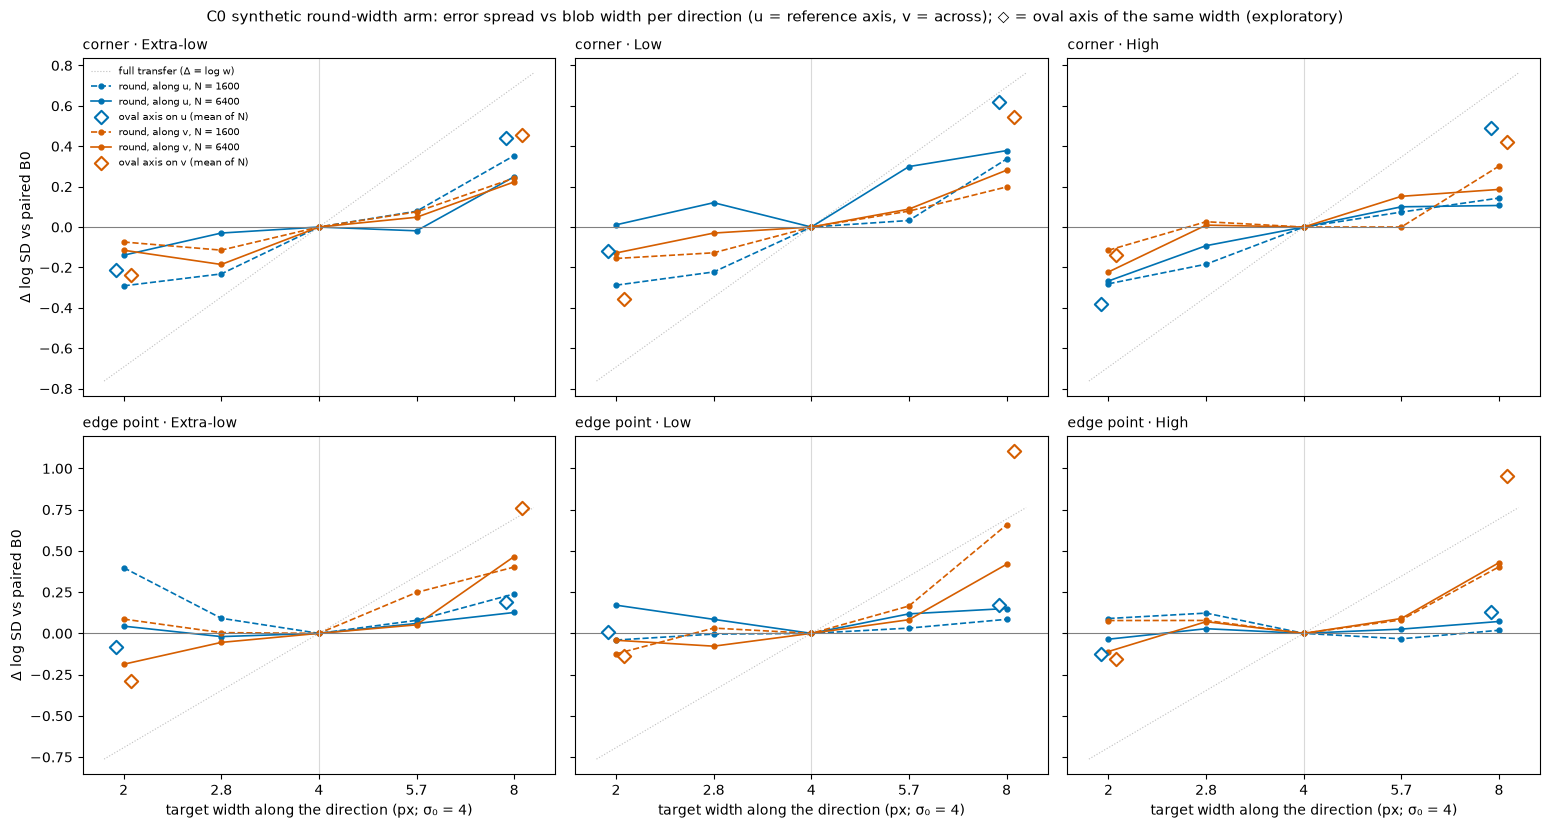

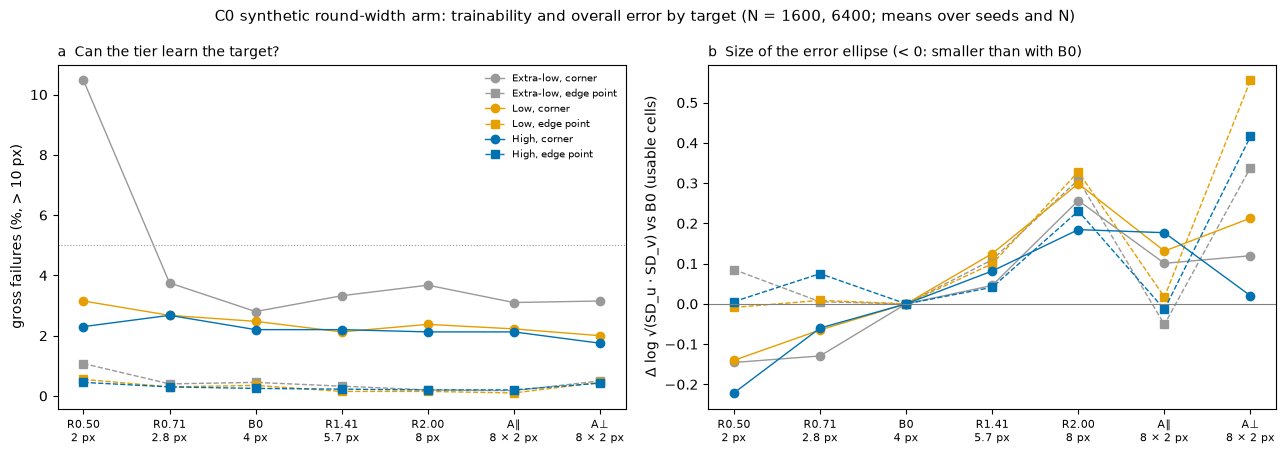

In [4]:
AGG = Path(RUN_ROOT) / "synth_summary_RW"
AGG.mkdir(exist_ok=True)
_LOCK = AGG / ".analysis.lock"
n_done = sum((Path(RUN_ROOT) / r / "DONE").exists() for r in RUN_TABLE.run_id)
missing_base = [r for r in PAIRED.run_id if not (Path(RUN_ROOT) / r / "DONE").exists()]
print(f"round-width runs done: {n_done} of {len(RUN_TABLE)} | paired mechanism-study runs present: "
      f"{len(PAIRED) - len(missing_base)} of {len(PAIRED)}")
if missing_base:
    print("missing paired runs (unpack synth_base_light.tgz next to the round-width runs):", missing_base[:6],
          "..." if len(missing_base) > 6 else "")

def _acquire_lock(stale_s=3600):
    if _LOCK.exists() and time.time() - _LOCK.stat().st_mtime > stale_s:
        _LOCK.unlink(missing_ok=True)
    try:
        os.close(os.open(_LOCK, os.O_CREAT | os.O_EXCL | os.O_WRONLY))
        return True
    except FileExistsError:
        print("another notebook is running the analysis now; skipped here")
        return False

def load_cells(table, round_width_arm):
    cells = []
    for _, run in table.iterrows():
        d = Path(RUN_ROOT) / run.run_id
        lines = (d / "DONE").read_text().split()
        assert lines[0] == SYNTH_HASH, f"{run.run_id}: protocol differs"
        if round_width_arm:
            assert len(lines) >= 3 and lines[2] == RW_HASH, f"{run.run_id}: round-width spec differs"
        p = pd.read_csv(d / "predictions_test.csv.gz")
        p["r"] = np.hypot(p.e_u, p.e_v)
        for k, g in p.groupby("landmark"):
            ok = g[g.r <= GROSS_PX]
            cells.append({"run_id": run.run_id, "tier": run.tier, "n_train": int(run.n_train), "seed": int(run.seed), "arm": run.arm,
                          "width_factor": RW_FACTOR.get(run.arm, 1.0 if run.arm == "B0" else np.nan), "landmark": LM_NAMES[k],
                          "fail_rate": 1 - len(ok) / len(g), "mre_px": g.r.mean(),
                          "sd_u": ok.e_u.std(ddof=1) if len(ok) > 2 else np.nan,
                          "sd_v": ok.e_v.std(ddof=1) if len(ok) > 2 else np.nan})
    return cells

def tci(x):
    """mean and half-width of the 95 % t interval (nan if fewer than 2 values)."""
    x = np.asarray(x, float); x = x[np.isfinite(x)]
    if len(x) < 2:
        return (float(x.mean()) if len(x) else np.nan), np.nan
    from scipy import stats as _st
    return float(x.mean()), float(_st.t.ppf(0.975, len(x) - 1) * x.std(ddof=1) / math.sqrt(len(x)))

assert n_done == len(RUN_TABLE) and not missing_base, "download all round-width runs into RUN_ROOT first"
HAVE_LOCK = _acquire_lock()
if HAVE_LOCK:
    try:
        H = math.log(2)
        CELLS = pd.DataFrame(load_cells(RUN_TABLE, True) + load_cells(PAIRED, False))
        CELLS["gm_sd"] = np.sqrt(CELLS.sd_u * CELLS.sd_v)
        CELLS.round(5).to_csv(AGG / "synth_RW_cells.csv", index=False)
        key = ["tier", "n_train", "seed", "landmark"]
        b0 = CELLS[CELLS.arm == "B0"].set_index(key)
        ok_cell = lambda c: c.fail_rate <= 0.05 and np.isfinite(c.sd_u) and np.isfinite(c.sd_v)

        # observations: round arms on both directions; ovals on their long and short axes
        obs = []
        for _, c in CELLS[CELLS.arm != "B0"].iterrows():
            b = b0.loc[tuple(c[k] for k in key)]
            usable = ok_cell(c) and ok_cell(b)
            if c.arm in RW_FACTOR:
                for dr in ("u", "v"):
                    obs.append({**{k: c[k] for k in key}, "target": "round", "arm": c.arm, "direction": dr, "axis": "round",
                                "x": math.log(c.width_factor), "usable": usable,
                                "dlog_sd": math.log(c[f"sd_{dr}"] / b[f"sd_{dr}"]) if usable else np.nan})
            else:
                long_ax, short_ax = ("u", "v") if c.arm == "Apar" else ("v", "u")
                for axis, dr, x in (("long", long_ax, H), ("short", short_ax, -H)):
                    obs.append({**{k: c[k] for k in key}, "target": "oval", "arm": c.arm, "direction": dr, "axis": axis,
                                "x": x, "usable": usable,
                                "dlog_sd": math.log(c[f"sd_{dr}"] / b[f"sd_{dr}"]) if usable else np.nan})
        OBS = pd.DataFrame(obs)
        OBS.round(5).to_csv(AGG / "synth_RW_axis_observations.csv", index=False)

        # (1) round size response: slopes through the origin, narrowing and widening separately
        rows = []
        for (tier, n, lm, dr), g in OBS[(OBS.target == "round") & OBS.usable].groupby(["tier", "n_train", "landmark", "direction"]):
            row = {"tier": tier, "n_train": n, "landmark": lm, "direction": dr, "n_obs": len(g)}
            for name, h in (("a_narrow", g[g.x < 0]), ("a_wide", g[g.x > 0])):
                row[name] = float((h.x * h.dlog_sd).sum() / (h.x ** 2).sum()) if len(h) else np.nan
                row[f"{name}_n"] = len(h)
            rows.append(row)
        SLOPES = pd.DataFrame(rows)
        oval = OBS[(OBS.target == "oval") & OBS.usable]
        ov = (oval.assign(a=oval.dlog_sd / oval.x).groupby(["tier", "n_train", "landmark", "direction", "axis"]).a.mean()
              .unstack("axis").rename(columns={"short": "oval_a_narrow", "long": "oval_a_wide"}).reset_index())
        SLOPES = SLOPES.merge(ov, on=["tier", "n_train", "landmark", "direction"], how="left")
        SLOPES.round(4).to_csv(AGG / "synth_RW_slopes.csv", index=False)

        # (2) round vs oval along the same direction at the same width (paired by tier, N, seed, landmark)
        rr = OBS[OBS.target == "round"].set_index(key + ["arm", "direction"]).dlog_sd
        cmp_rows = []
        for _, o in OBS[OBS.target == "oval"].iterrows():
            ra = "R0.50" if o.axis == "short" else "R2.00"
            r_ = rr.get(tuple(o[k] for k in key) + (ra, o.direction), np.nan)
            cmp_rows.append({**{k: o[k] for k in key}, "oval_arm": o.arm, "axis": o.axis, "direction": o.direction, "round_arm": ra,
                             "dlog_oval": o.dlog_sd, "dlog_round": r_, "diff_oval_minus_round": o.dlog_sd - r_})
        CMP = pd.DataFrame(cmp_rows)
        CMP.round(5).to_csv(AGG / "synth_RW_round_vs_oval_pairs.csv", index=False)
        summ = []
        for (tier, lm, axis), g in CMP.groupby(["tier", "landmark", "axis"]):
            m, hw = tci(g.diff_oval_minus_round)
            mo, _ = tci(g.dlog_oval); mr, _ = tci(g.dlog_round)
            summ.append({"tier": tier, "landmark": lm, "oval_axis": axis, "n_pairs": int(g.diff_oval_minus_round.notna().sum()),
                         "mean_dlog_oval": mo, "mean_dlog_round": mr, "diff_oval_minus_round": m, "ci95_half": hw})
        CMPS = pd.DataFrame(summ)
        CMPS.round(4).to_csv(AGG / "synth_RW_round_vs_oval.csv", index=False)

        # (3) trainability and (4) overall error per target, relative to B0
        FAILS = CELLS.pivot_table(index=["tier", "n_train"], columns="arm", values="fail_rate", aggfunc="mean")
        order = ["R0.50", "R0.71", "B0", "R1.41", "R2.00", "Apar", "Aperp"]
        FAILS = FAILS[[a for a in order if a in FAILS.columns]]
        FAILS.round(4).to_csv(AGG / "synth_RW_fail_rates.csv")
        rel = CELLS.merge(b0[["gm_sd", "mre_px"]].rename(columns={"gm_sd": "gm_b0", "mre_px": "mre_b0"}).reset_index(), on=key)
        rel["dlog_gm_sd"] = np.log(rel.gm_sd / rel.gm_b0)
        rel["dlog_mre"] = np.log(rel.mre_px / rel.mre_b0)
        rel["usable"] = rel.fail_rate <= 0.05
        OVERALL = (rel[rel.arm != "B0"].groupby(["tier", "landmark", "arm"])
                   .apply(lambda g: pd.Series({"usable_cells": int(g.usable.sum()), "cells": len(g),
                                               "dlog_gm_sd": g[g.usable].dlog_gm_sd.mean(), "dlog_mre": g.dlog_mre.mean(),
                                               "fail_rate": g.fail_rate.mean()}), include_groups=False).reset_index())
        OVERALL.round(4).to_csv(AGG / "synth_RW_overall.csv", index=False)
        BEST = []
        for (tier, lm), g in OVERALL[OVERALL.usable_cells == OVERALL.cells].groupby(["tier", "landmark"]):
            rd, ovl = g[g.arm.isin(list(RW_FACTOR))], g[g.arm.isin(["Apar", "Aperp"])]
            if len(rd) and len(ovl):
                br, bo = rd.loc[rd.dlog_gm_sd.idxmin()], ovl.loc[ovl.dlog_gm_sd.idxmin()]
                BEST.append({"tier": tier, "landmark": lm, "best_round": br.arm, "best_round_dlog_gm_sd": br.dlog_gm_sd,
                             "best_oval": bo.arm, "best_oval_dlog_gm_sd": bo.dlog_gm_sd,
                             "oval_minus_round": bo.dlog_gm_sd - br.dlog_gm_sd})
        BEST = pd.DataFrame(BEST)
        BEST.round(4).to_csv(AGG / "synth_RW_best_round_vs_oval.csv", index=False)

        # figure 1: size response per direction (round curves) with the oval axes overlaid at the same widths
        tiers = list(TIER_BASE)
        dcol = {"u": "#0072B2", "v": "#D55E00"}
        fig, axs = plt.subplots(len(LM_NAMES), len(tiers), figsize=(5.2 * len(tiers), 4.2 * len(LM_NAMES)), sharex=True, sharey="row", squeeze=False)
        xs = np.array([math.log2(f) for f in RW_FACTORS] + [0.0])
        for r, lm in enumerate(LM_NAMES):
            for j, tier in enumerate(tiers):
                ax = axs[r, j]
                ax.plot([-1.1, 1.1], [-1.1 * H, 1.1 * H], color="0.75", lw=0.8, ls=":", label="full transfer (Δ = log w)")
                for dr in ("u", "v"):
                    for n, ls in zip(RW_N, ("--", "-")):
                        g = OBS[(OBS.target == "round") & (OBS.tier == tier) & (OBS.landmark == lm) & (OBS.direction == dr)
                                & (OBS.n_train == n)]
                        m = g.groupby("x").dlog_sd.mean()
                        pts = pd.concat([m, pd.Series({0.0: 0.0})]).sort_index()
                        ax.plot(np.log2(np.exp(pts.index)), pts.values, ls=ls, marker="o", ms=3.5, color=dcol[dr], lw=1.2,
                                label=f"round, along {dr}, N = {n}")
                    go = OBS[(OBS.target == "oval") & (OBS.tier == tier) & (OBS.landmark == lm) & (OBS.direction == dr)]
                    mo = go.groupby("x").dlog_sd.mean()
                    ax.scatter(np.log2(np.exp(mo.index)) + (0.04 if dr == "v" else -0.04), mo.values, marker="D", s=46,
                               facecolor="white", edgecolor=dcol[dr], lw=1.5, zorder=5, label=f"oval axis on {dr} (mean of N)")
                ax.axhline(0, color="0.5", lw=0.8); ax.axvline(0, color="0.85", lw=0.8)
                ax.set_xticks([-1, -0.5, 0, 0.5, 1])
                ax.set_xticklabels([f"{SIGMA0_PX * 2 ** t:.2g}" for t in (-1, -0.5, 0, 0.5, 1)])
                ax.set_title(f"{lm} · {tier}", fontsize=10, loc="left")
                if r == len(LM_NAMES) - 1:
                    ax.set_xlabel("target width along the direction (px; σ₀ = %g)" % SIGMA0_PX)
                if j == 0:
                    ax.set_ylabel("Δ log SD vs paired B0")
        axs[0, 0].legend(fontsize=7, frameon=False, loc="upper left")
        fig.suptitle("C0 synthetic round-width arm: error spread vs blob width per direction (u = reference axis, v = across); "
                     "◇ = oval axis of the same width (exploratory)", fontsize=11)
        fig.tight_layout()
        fig.savefig(AGG / "synth_RW_size_response.png", dpi=150, bbox_inches="tight")

        # figure 2: trainability and overall error size by target
        fig2, axs2 = plt.subplots(1, 2, figsize=(13, 4.6))
        lmk = {"corner": "o", "edge point": "s"}
        tcol = dict(zip(tiers, ["#999999", "#E69F00", "#0072B2"][-len(tiers):]))
        xr = {a: i for i, a in enumerate(order)}
        for tier in tiers:
            for lm in LM_NAMES:
                g = OVERALL[(OVERALL.tier == tier) & (OVERALL.landmark == lm)].set_index("arm")
                fr = CELLS[(CELLS.tier == tier) & (CELLS.landmark == lm)].groupby("arm").fail_rate.mean()
                a_ = [a for a in order if a in fr.index]
                axs2[0].plot([xr[a] for a in a_], [fr[a] * 100 for a in a_], marker=lmk[lm], color=tcol[tier], lw=1,
                             ls="-" if lm == "corner" else "--", label=f"{tier}, {lm}")
                a2 = [a for a in order if a == "B0" or a in g.index]
                axs2[1].plot([xr[a] for a in a2], [0.0 if a == "B0" else g.loc[a, "dlog_gm_sd"] for a in a2], marker=lmk[lm],
                             color=tcol[tier], lw=1, ls="-" if lm == "corner" else "--")
        for ax in axs2:
            ax.set_xticks(range(len(order)))
            ax.set_xticklabels([f"{a}\n{RW_FACTOR.get(a, 1.0) * SIGMA0_PX:.2g} px" if a not in ("Apar", "Aperp") else
                                {"Apar": "A∥", "Aperp": "A⊥"}[a] + f"\n{2 * SIGMA0_PX:.2g} × {SIGMA0_PX / 2:.2g} px" for a in order], fontsize=8)
        axs2[0].axhline(5, color="0.6", lw=0.8, ls=":"); axs2[0].set_ylabel("gross failures (%, > 10 px)")
        axs2[0].set_title("a  Can the tier learn the target?", fontsize=10, loc="left")
        axs2[0].legend(fontsize=7, frameon=False)
        axs2[1].axhline(0, color="0.5", lw=0.8)
        axs2[1].set_ylabel("Δ log √(SD_u · SD_v) vs B0 (usable cells)")
        axs2[1].set_title("b  Size of the error ellipse (< 0: smaller than with B0)", fontsize=10, loc="left")
        fig2.suptitle(f"C0 synthetic round-width arm: trainability and overall error by target (N = {', '.join(map(str, RW_N))}; "
                      f"means over seeds and N)", fontsize=11)
        fig2.tight_layout()
        fig2.savefig(AGG / "synth_RW_overall.png", dpi=150, bbox_inches="tight")

        summary = {"protocol_hash": SYNTH_HASH, "rw_hash": RW_HASH, "runs": len(RUN_TABLE), "paired_runs": len(PAIRED),
                   "width_px": [f * SIGMA0_PX for f in RW_FACTORS], "fail_rates": FAILS.round(4).reset_index().to_dict("records"),
                   "round_vs_oval": CMPS.round(4).to_dict("records"), "best_round_vs_oval": BEST.round(4).to_dict("records"),
                   "slopes_mean": SLOPES.groupby(["tier", "landmark", "direction"])[["a_narrow", "a_wide", "oval_a_narrow", "oval_a_wide"]]
                   .mean().round(4).reset_index().to_dict("records")}
        (AGG / "synth_RW_summary.json").write_text(json.dumps(summary, indent=1, default=float))
        display(FAILS.round(3))
        display(SLOPES.groupby(["landmark", "tier", "direction"])[["a_narrow", "oval_a_narrow", "a_wide", "oval_a_wide"]].mean().round(3))
        display(CMPS.round(3))
        display(BEST.round(3))
    finally:
        _LOCK.unlink(missing_ok=True)